<a href="https://colab.research.google.com/github/MrdnvShafiga/Real-Time-Furniture-Classification-System-Computer-Vision/blob/main/Real_Time_Furniture_Classification_System_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q torchmetrics

In [2]:
import kagglehub

path = kagglehub.dataset_download("oortdatahub/furniture-dataset-for-multi-angle-ai-training")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'furniture-dataset-for-multi-angle-ai-training' dataset.
Path to dataset files: /kaggle/input/furniture-dataset-for-multi-angle-ai-training


In [3]:
import os
import re
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torchvision
import torchmetrics
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from collections import defaultdict
from sklearn.metrics import classification_report, confusion_matrix

In [4]:
if torch.cuda.is_available():
  device = 'cuda'
elif torch.backends.mps.is_available():
  device = 'mps'
else:
  device = 'cpu'

In [5]:
device

'cuda'

In [6]:
data_dir = None
for root, dirs, files in os.walk(path):
  if 'Bar Stool Dataset' in dirs:
    data_dir = root
    break
if data_dir is None:
  data_dir = path
print(data_dir)
print(sorted(os.listdir(data_dir)))

/kaggle/input/furniture-dataset-for-multi-angle-ai-training
['Bar Stool Dataset', 'Bed Dataset', 'Chair Dataset', 'Coffee Table Dataset', 'Dinning Table DataSet', 'Dresser Dataset']


In [7]:
weights = torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1
eval_transform = weights.transforms()
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [8]:
base_dataset = datasets.ImageFolder(root=data_dir)
class_names = [re.sub(r'\s*dataset\s*$', '', c, flags=re.I).replace('Dinning', 'Dining') for c in base_dataset.classes]
num_classes = len(class_names)
class_names, len(base_dataset)

(['Bar Stool', 'Bed', 'Chair', 'Coffee Table', 'Dining Table', 'Dresser'],
 10364)

In [9]:
counts = np.bincount(base_dataset.targets)
dict(zip(class_names, counts.tolist()))

{'Bar Stool': 1665,
 'Bed': 2862,
 'Chair': 980,
 'Coffee Table': 528,
 'Dining Table': 2355,
 'Dresser': 1974}

In [10]:
random.seed(42)
groups = defaultdict(lambda: defaultdict(list))
for idx, (p, y) in enumerate(base_dataset.samples):
  groups[y][os.path.dirname(p)].append(idx)

train_idx, val_idx, test_idx = [], [], []
for y, seqs in groups.items():
  keys = sorted(seqs)
  random.shuffle(keys)
  if len(keys) < 3:
    idxs = [i for k in keys for i in seqs[k]]
    random.shuffle(idxs)
    n_t = int(len(idxs) * 0.15)
    test_idx += idxs[:n_t]
    val_idx += idxs[n_t:2 * n_t]
    train_idx += idxs[2 * n_t:]
    continue
  n_test = max(1, round(len(keys) * 0.15))
  n_val = max(1, round(len(keys) * 0.15))
  for k in keys[:n_test]:
    test_idx += seqs[k]
  for k in keys[n_test:n_test + n_val]:
    val_idx += seqs[k]
  for k in keys[n_test + n_val:]:
    train_idx += seqs[k]

len(train_idx), len(val_idx), len(test_idx)

(6973, 1617, 1774)

In [11]:
train_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=train_transform), train_idx)
valid_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=eval_transform), val_idx)
test_dataset = Subset(datasets.ImageFolder(root=data_dir, transform=eval_transform), test_idx)

In [12]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
valid_loader = DataLoader(valid_dataset, batch_size=32, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, num_workers=2)

In [13]:
images, labels = next(iter(train_loader))
images.shape, labels[:10].tolist()

(torch.Size([32, 3, 224, 224]), [5, 1, 2, 4, 2, 0, 4, 1, 1, 4])

In [14]:
torch.manual_seed(42)
model = torchvision.models.convnext_base(weights=weights)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, num_classes)
model = model.to(device)

Downloading: "https://download.pytorch.org/models/convnext_base-6075fbad.pth" to /root/.cache/torch/hub/checkpoints/convnext_base-6075fbad.pth


100%|██████████| 338M/338M [00:03<00:00, 90.1MB/s]


In [15]:
def evaluate_tm(model, data_loader, metric):
  model.eval()
  metric.reset()
  with torch.no_grad():
    for X_batch, y_batch in data_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      metric.update(y_pred, y_batch)
  return metric.compute()

In [16]:
def train(model, optimizer, loss_fn, metric, train_loader, valid_loader, n_epochs):
  history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
  best_acc = 0.0
  best_state = copy.deepcopy(model.state_dict())
  for epoch in range(n_epochs):
    total_loss = 0.0
    metric.reset()
    model.train()
    for X_batch, y_batch in train_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      loss = loss_fn(y_pred, y_batch)
      total_loss += loss.item()
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
      metric.update(y_pred, y_batch)
    history["train_losses"].append(total_loss / len(train_loader))
    history["train_metrics"].append(metric.compute().item())
    valid_acc = evaluate_tm(model, valid_loader, metric).item()
    history["valid_metrics"].append(valid_acc)
    if valid_acc > best_acc:
      best_acc = valid_acc
      best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch+1}/{n_epochs}, "
          f"train loss: {history['train_losses'][-1]:.4f}, "
          f"train acc: {history['train_metrics'][-1]:.4f}, "
          f"valid acc: {valid_acc:.4f}")
  model.load_state_dict(best_state)
  return history

In [17]:
loss_fn = nn.CrossEntropyLoss()
accuracy = torchmetrics.Accuracy(task='multiclass', num_classes=num_classes).to(device)

In [18]:
for p in model.features.parameters():
  p.requires_grad = False
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
history1 = train(model, optimizer, loss_fn, accuracy, train_loader, valid_loader, n_epochs=4)

Epoch 1/4, train loss: 0.3508, train acc: 0.9118, valid acc: 0.8442
Epoch 2/4, train loss: 0.1542, train acc: 0.9531, valid acc: 0.8584
Epoch 3/4, train loss: 0.1270, train acc: 0.9606, valid acc: 0.8745
Epoch 4/4, train loss: 0.1118, train acc: 0.9633, valid acc: 0.8738


In [19]:
for p in model.features[-2:].parameters():
  p.requires_grad = True
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-5)
history2 = train(model, optimizer, loss_fn, accuracy, train_loader, valid_loader, n_epochs=4)

Epoch 1/4, train loss: 0.1086, train acc: 0.9656, valid acc: 0.8769
Epoch 2/4, train loss: 0.1022, train acc: 0.9672, valid acc: 0.8738
Epoch 3/4, train loss: 0.0975, train acc: 0.9702, valid acc: 0.8800
Epoch 4/4, train loss: 0.0944, train acc: 0.9709, valid acc: 0.8837


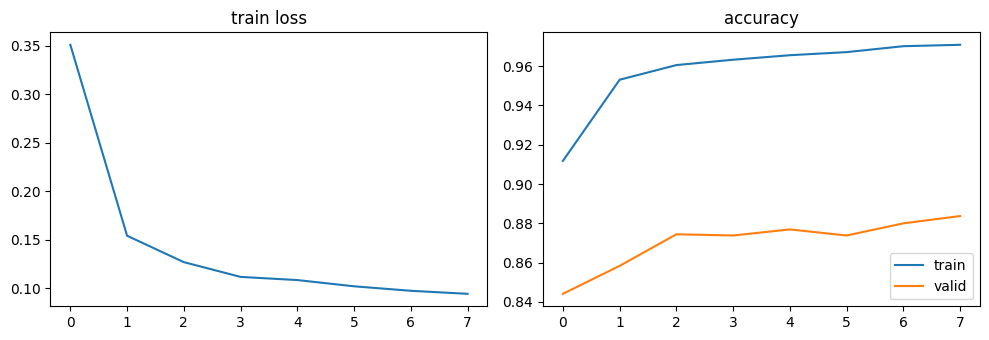

In [20]:
train_losses = history1["train_losses"] + history2["train_losses"]
train_accs = history1["train_metrics"] + history2["train_metrics"]
valid_accs = history1["valid_metrics"] + history2["valid_metrics"]

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.plot(train_losses)
plt.title('train loss')
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='train')
plt.plot(valid_accs, label='valid')
plt.title('accuracy')
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

test_acc = evaluate_tm(model, test_loader, accuracy).item()
print(f'Test accuracy: {test_acc:.2%}')

Test accuracy: 89.46%


In [23]:
y_true, y_pred = [], []
model.eval()
with torch.no_grad():
  for X_batch, y_batch in test_loader:
    preds = model(X_batch.to(device)).argmax(dim=1).cpu()
    y_pred += preds.tolist()
    y_true += y_batch.tolist()

labels_all = list(range(num_classes))
print(classification_report(y_true, y_pred, labels=labels_all, target_names=class_names, digits=3, zero_division=0))

              precision    recall  f1-score   support

   Bar Stool      0.858     0.965     0.908       200
         Bed      0.964     0.995     0.979       400
       Chair      0.926     0.935     0.930       200
Coffee Table      0.871     0.270     0.412       200
Dining Table      0.776     0.968     0.861       400
     Dresser      0.987     0.984     0.985       374

    accuracy                          0.895      1774
   macro avg      0.897     0.853     0.846      1774
weighted avg      0.899     0.895     0.876      1774



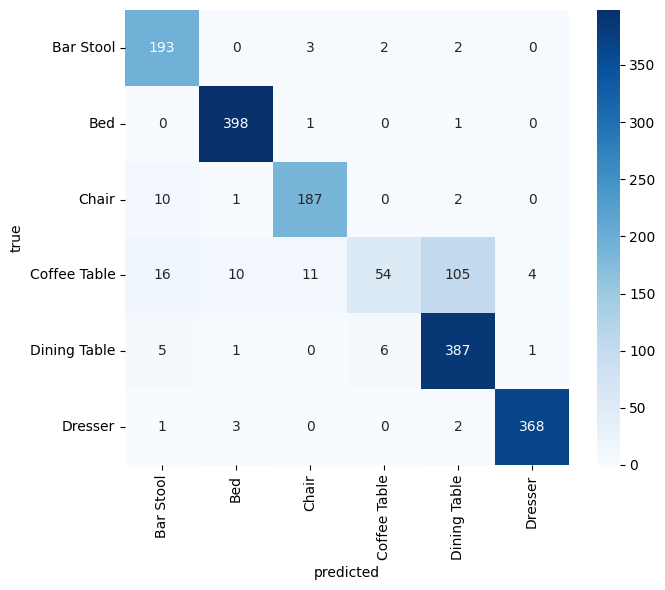

In [24]:
cm = confusion_matrix(y_true, y_pred, labels=labels_all)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('predicted')
plt.ylabel('true')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

In [25]:
def denormalize(image, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]):
  return image * torch.tensor(std).view(-1, 1, 1) + torch.tensor(mean).view(-1, 1, 1)

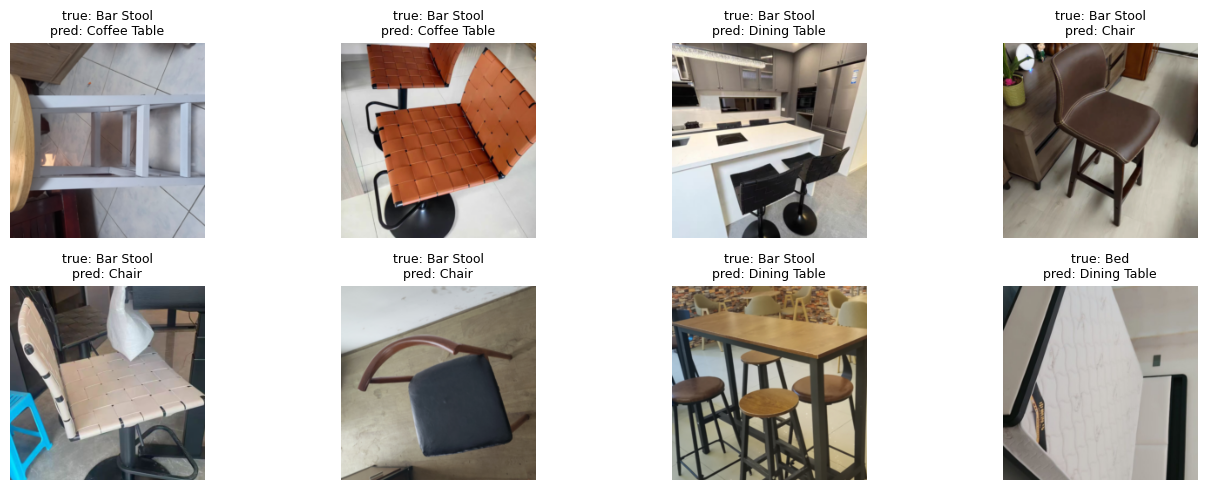

In [26]:
wrong = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p][:8]
plt.figure(figsize=(14, 5))
for k, i in enumerate(wrong):
  img, _ = test_dataset[i]
  plt.subplot(2, 4, k + 1)
  plt.imshow(denormalize(img).permute(1, 2, 0).clamp(0, 1))
  plt.title(f'true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]}', fontsize=9)
  plt.axis('off')
plt.tight_layout()
plt.show()

In [27]:
torch.save(model.cpu(), 'furniture_detection.pth')
print(f'class_names = {class_names}')

from google.colab import files
files.download('furniture_detection.pth')
files.download('confusion_matrix.png')

class_names = ['Bar Stool', 'Bed', 'Chair', 'Coffee Table', 'Dining Table', 'Dresser']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>